# 07 · ENSAYO de la prueba con video (tarea 2.6) — DATOS SIMULADOS, NO ES UNA EVALUACIÓN

> **⚠ ENSAYO.** Aún no existen el video ni las fotos de los voluntarios. Este cuaderno solo **comprueba que el código funciona** de punta a punta
> con un video **sintético** construido con fotos del propio dataset. Sus cifras **no son resultados del sistema** y no deben citarse como tales.

- "Voluntarios" simulados: `ENSAYO_V01` (Hugh Jackman) y `ENSAYO_V02` (Natalie Portman). Son identidades del dataset sin plantilla entre las 24 registradas.
  Se registran con 10 fotos de *Original Images* (sin recortar), mediante el script de registro.
- "No registrados": Courtney Cox y Kashyap.
- Video: 5 fotos por tramo, cada una mostrada 1,2 s a 15 fps con zoom, desplazamiento, ruido y cambio de brillo. La última foto de cada tramo va desenfocada.
  Las fotos del video y las de registro pertenecen a grupos de casi duplicados distintos.
- Las fotos de Hugh Jackman, Natalie Portman, Courtney Cox y Kashyap formaron parte del conjunto de **prueba** de la tarea 2.5, que ya se
  ejecutó; aquí no se evalúa nada con ellas, solo se ensaya el código.
- **Privacidad:** no se muestra ni se guarda ninguna imagen o recorte, solo métricas agregadas. Los datos del ensayo están en `data/ensayo/`, que git ignora.

Parámetros fijos: MTCNN con margen 0, 1 de cada 3 fotogramas, ventana de 5 fotogramas procesados con votación por mayoría (≥ 3 de 5) y umbral oficial **0,5514**.

In [1]:
import os, sys, json, time, subprocess, platform
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from src import config as C, data as D, pipeline as P, video as VID, video_verificacion as VV
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True})
pd.set_option("display.width", 200)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
PKG = C.MODELS_DIR / "verificador_facenet_vggface2"
def graficar(met, titulo, archivo):
    """Solo metricas AGREGADAS (sin imagenes ni datos por fotograma)."""
    t = met[met.persona == "todas"].copy()
    t["etiqueta"] = t.tipo + " (" + t.metrica + ")"
    fig, ax = plt.subplots(figsize=(9, 3.8))
    niveles = ["fotograma", "ventana"]; col = {"fotograma": "#2a78d6", "ventana": "#eb6834"}
    etiquetas = list(dict.fromkeys(t.etiqueta))
    y = np.arange(len(etiquetas))
    for k, nv in enumerate(niveles):
        d = t[t.nivel == nv].set_index("etiqueta").reindex(etiquetas)
        ax.barh(y + (k - 0.5) * 0.38, d.tasa * 100, height=0.36, color=col[nv], label=nv, edgecolor="white", linewidth=2)
        for yy, (v, e, n) in zip(y + (k - 0.5) * 0.38, zip(d.tasa, d.errores, d.n)):
            if not np.isnan(v): ax.text(v * 100 + 0.3, yy, f"{v*100:.1f} % ({int(e)}/{int(n)})", va="center", fontsize=7, color="#333")
    ax.set_yticks(y); ax.set_yticklabels(etiquetas, fontsize=8); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_xlabel("tasa de error (%)"); ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.set_title(titulo, loc="left", fontsize=10)
    plt.tight_layout(); plt.savefig(C.FIGS / archivo); plt.show()

def fmt(met):
    m = met.copy(); m["tasa_%"] = (m.tasa * 100).round(2); m["IC95_%"] = m.IC95.map(lambda t: f"{t[0]*100:.1f}-{t[1]*100:.1f}")
    return m.drop(columns=["tasa", "IC95"])
print("ENSAYO | dispositivo", DEV, "| umbral oficial", C.UMBRAL_OFICIAL, "| cada_n", C.VIDEO_CADA_N, "| ventana", C.VIDEO_VENTANA)

ENSAYO | dispositivo cuda | umbral oficial 0.551421 | cada_n 3 | ventana 5


## 1. Compatibilidad del recorte MTCNN con el recorte del dataset (solo imágenes de VALIDACIÓN)

El umbral se fijó con los recortes de `Faces`. En video el recorte lo hace MTCNN, así que se comprueba qué margen de MTCNN produce embeddings
más parecidos a los de `Faces` para las **mismas fotos**. Se usan 150 fotos de validación, tomando su original sin recortar.

In [2]:
va = D.load_split_table(); va = va[va.split == "val"].sample(150, random_state=C.SEED).reset_index(drop=True)
vf = P.Verifier(PKG, device=DEV)
Ef = vf.embed(D.load_images([str(C.FACES_DIR / f) for f in va.filename])).cpu().numpy()
filas = []
for margen in [0, 10, 20, 32, 44]:
    cr = VID.FaceCropper(DEV, margin=margen); cos = []
    for k, r in va.iterrows():
        c, _ = cr(D.read_rgb(C.ORIGINALS_DIR / r.person / r.filename))
        if c is not None: cos.append(float(vf.embed(c[None]).cpu().numpy()[0] @ Ef[k]))
    cos = np.array(cos)
    filas.append({"margen": margen, "detectados": len(cos), "n": len(va), "coseno_mediana": np.median(cos), "coseno_p10": np.percentile(cos, 10), "coseno_min": cos.min()})
marg = pd.DataFrame(filas); marg.to_csv(C.DOCS / "08_margen_mtcnn_validacion.csv", index=False)
assert marg.loc[marg.coseno_mediana.idxmax(), "margen"] == C.VIDEO_MTCNN_MARGEN, "el margen fijado en config no es el mejor"
marg.round(3)

,margen,detectados,n,coseno_mediana,coseno_p10,coseno_min
0,0,150,150,0.989,0.967,-0.105
1,10,150,150,0.974,0.952,-0.138
2,20,150,150,0.959,0.927,-0.098
3,32,150,150,0.944,0.908,-0.048
4,44,150,150,0.926,0.882,-0.104


## 2. Datos de ensayo y registro de los voluntarios simulados (con el script de registro)

In [3]:
from src import ensayo_video as EN
info_ens = EN.build()
print("ENSAYO:", {k: (str(v) if isinstance(v, Path) else v) for k, v in info_ens.items() if k not in ("anotaciones_df", "fotos_registro")})
ARCH = "plantillas_voluntarios_ENSAYO.npz"     # archivo distinto del real (plantillas_voluntarios.npz)
reg = []
for vid_id, carpeta in info_ens["fotos_registro"].items():
    r = subprocess.run([sys.executable, "-m", "src.registro_voluntario", "--fotos", str(carpeta), "--id", vid_id,
                        "--archivo", ARCH, "--reemplazar", "--dispositivo", DEV], cwd=ROOT, capture_output=True, text=True)
    assert r.returncode == 0, r.stderr[-2000:]
    out = json.loads(r.stdout[r.stdout.index("{"):]); reg.append({k: out[k] for k in ["id", "n_fotos", "n_rostros", "segundos"]})
pd.DataFrame(reg)

ENSAYO: {'carpeta': 'D:\\IA\\FaceID\\data\\ensayo', 'video': 'D:\\IA\\FaceID\\data\\ensayo\\video_ensayo.mp4', 'anotaciones': 'D:\\IA\\FaceID\\data\\ensayo\\anotaciones_ensayo.csv', 'duracion_s': 25.866666666666667, 'fotogramas': 388, 'fotos_video_por_tramo': 5, 'fotos_registro_por_voluntario': 10}


,id,n_fotos,n_rostros,segundos
0,ENSAYO_V01,10,10,18.67
1,ENSAYO_V02,10,10,16.25


In [4]:
# Las 24 plantillas del dataset siguen intactas y separadas de las de voluntarios
z = np.load(PKG / "plantillas.npz"); zv = np.load(PKG / ARCH)
print("dataset:", z["T"].shape, "| voluntarios ENSAYO:", zv["T"].shape, list(zv["usuarios"]))
v_all = P.Verifier(PKG, device=DEV, voluntarios=ARCH)
assert v_all.users[:24] == [str(u) for u in z["usuarios"]] and np.allclose(v_all.T[:24].cpu().numpy(), z["T"])
# El guardián de privacidad rechaza rutas del repositorio fuera de data/
try: VID.check_private_path(C.DOCS); print("ERROR: no bloqueó")
except ValueError as e: print("Guardián de privacidad OK:", str(e)[:90], "...")

dataset: (24, 512) | voluntarios ENSAYO: (2, 512) [np.str_('ENSAYO_V01'), np.str_('ENSAYO_V02')]


Guardián de privacidad OK: D:\IA\FaceID\docs\sprint2 esta dentro del repositorio y fuera de data/: los datos personal ...


## 3. Video de ensayo: detección, verificación y votación por ventana

In [5]:
t0 = time.time()
info, met, sin, frames, comps = VV.run(info_ens["video"], info_ens["anotaciones"], voluntarios=ARCH, device=DEV)
print(f"ENSAYO | {time.time()-t0:.1f} s |", info)
met.to_csv(C.DOCS / "08_ENSAYO_metricas_video.csv", index=False); sin.to_csv(C.DOCS / "08_ENSAYO_sin_rostro.csv", index=False)
fmt(met[met.persona == "todas"])

ENSAYO | 36.2 s | {'video_fps': 15.0, 'fotogramas_procesados': 120, 'cada_n': 3, 'ventana': 5, 'umbral': 0.551421, 'voluntarios': ['ENSAYO_V01', 'ENSAYO_V02'], 'segundos_por_fotograma_mediana': 0.14334210000015446, 'segundos_por_fotograma_p95': 0.2281174199990346, 'dispositivo': 'cuda'}


,nivel,tipo,persona,metrica,errores,n,tasa_%,IC95_%
0,fotograma,genuina,todas,FRR,6,60,10.00,3.8-20.5
1,fotograma,genuina (solo fotogramas con rostro),todas,FRR,6,60,10.00,3.8-20.5
4,fotograma,impostora externa,todas,FAR,0,120,0.00,0.0-3.0
7,fotograma,impostora interna,todas,FAR,0,60,0.00,0.0-6.0
10,fotograma,impostora vs dataset,todas,FAR,1,2880,0.03,0.0-0.2
15,ventana,genuina,todas,FRR,1,12,8.33,0.2-38.5
18,ventana,impostora externa,todas,FAR,0,24,0.00,0.0-14.2
21,ventana,impostora interna,todas,FAR,0,12,0.00,0.0-26.5
24,ventana,impostora vs dataset,todas,FAR,0,576,0.00,0.0-0.6


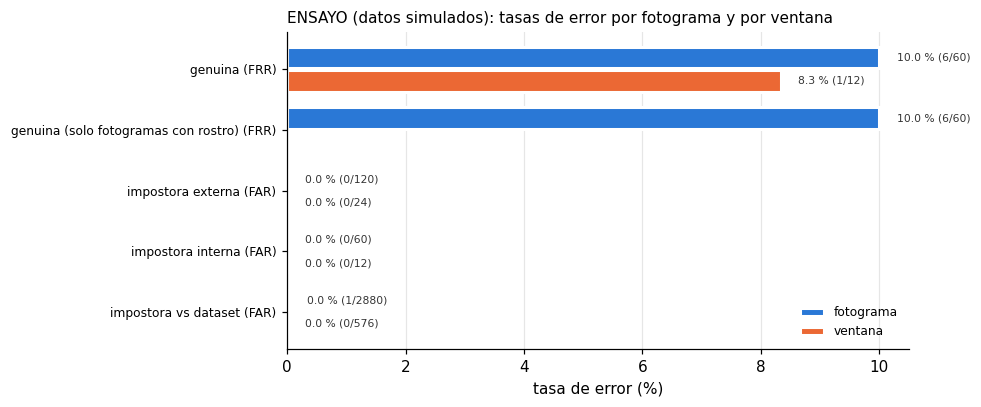

In [6]:
graficar(met, "ENSAYO (datos simulados): tasas de error por fotograma y por ventana", "08_ENSAYO_tasas_video.png")

Desglose por persona (seudónimo) y tasa de fotogramas sin rostro:

In [7]:
fmt(met[met.persona != "todas"]).sort_values(["nivel", "tipo", "persona"])

,nivel,tipo,persona,metrica,errores,n,tasa_%,IC95_%
2,fotograma,genuina,ENSAYO_V01,FRR,6,30,20.00,7.7-38.6
3,fotograma,genuina,ENSAYO_V02,FRR,0,30,0.00,0.0-11.6
5,fotograma,impostora externa,no registrado A,FAR,0,60,0.00,0.0-6.0
6,fotograma,impostora externa,no registrado B,FAR,0,60,0.00,0.0-6.0
8,fotograma,impostora interna,ENSAYO_V01,FAR,0,30,0.00,0.0-11.6
9,fotograma,impostora interna,ENSAYO_V02,FAR,0,30,0.00,0.0-11.6
11,fotograma,impostora vs dataset,ENSAYO_V01,FAR,0,720,0.00,0.0-0.5
12,fotograma,impostora vs dataset,ENSAYO_V02,FAR,0,720,0.00,0.0-0.5
13,fotograma,impostora vs dataset,no registrado A,FAR,0,720,0.00,0.0-0.5
14,fotograma,impostora vs dataset,no registrado B,FAR,1,720,0.14,0.0-0.8


In [8]:
sin

,persona,procesados,con_rostro,tasa_sin_rostro
0,ENSAYO_V01,30,30,0.0
1,ENSAYO_V02,30,30,0.0
2,no registrado A,30,30,0.0
3,no registrado B,30,30,0.0
4,todas,120,120,0.0


## 4. Tiempo por verificación **incluyendo la detección de rostro** (GPU y CPU)

Se miden 40 fotogramas del video de ensayo, de 640×480. El tiempo incluye MTCNN, recorte, embedding y coseno. El objetivo es ≤ 3 s por verificación.
Una decisión por ventana necesita 5 fotogramas procesados: unos 15 fotogramas de video, es decir 1 s a 15 fps, más 5 veces el tiempo de proceso.

In [9]:
ann = VID.read_annotations(info_ens["anotaciones"])
fr = VID.sample_frames(info_ens["video"], 40, C.VIDEO_CADA_N, ann)
tiempos = VID.timing(fr, lambda d: P.Verifier(PKG, device=d, voluntarios=ARCH), lambda d: VID.FaceCropper(d))
tiempos["cumple_3s_p95"] = tiempos.p95_s <= 3.0
tiempos["decision_ventana_s (proceso de 5 fotogramas)"] = 5 * tiempos.mediana_s
tiempos.to_csv(C.DOCS / "08_ENSAYO_tiempos_con_deteccion.csv", index=False); del fr
tiempos.round(4)

,dispositivo,n,sin_rostro,mediana_s,p95_s,max_s,cumple_3s_p95,decision_ventana_s (proceso de 5 fotogramas)
0,GPU,40,0,0.1541,0.1859,0.2035,True,0.7704
1,CPU,40,0,0.2097,0.2749,0.3076,True,1.0484


In [10]:
json.dump({"AVISO": "ENSAYO con datos simulados del dataset; no es una evaluación", "info": info, "registro": reg,
           "tiempos": tiempos.to_dict("records"), "margen_mtcnn": marg.to_dict("records")},
          open(C.DOCS / "08_ENSAYO_resumen.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False, default=str)
print("ENSAYO guardado (solo métricas agregadas).")

ENSAYO guardado (solo métricas agregadas).
